In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import os

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy.stats import spearmanr

# ── Semilla y rutas ────────────────────────────────────────────────
SEED = 42
np.random.seed(SEED)
rng  = np.random.default_rng(SEED)

FECHA_CORTE = pd.Timestamp("2025-12-31")
DATA_DIR    = Path("../data")
OUT_DIR     = Path("../outputs")
FIG_DIR     = Path("../figures")

os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

TASA_DESC_ANUAL   = 0.12   # 12 % anual para descuentos
HORIZONTE_ML_MESES = 12    # ventana de target para entrenamiento
MIN_HISTORIA_MESES = 36    # 3 años mínimos de historia
MIN_FUTURO_MESES   = 12    # meses mínimos de observación post-corte
HORIZONTE_CLV_ANOS = 3     # proyección final del CLV en años

print("Config OK")
print(f"  FECHA_CORTE         : {FECHA_CORTE.date()}")
print(f"  HORIZONTE_ML_MESES  : {HORIZONTE_ML_MESES}")
print(f"  MIN_HISTORIA_MESES  : {MIN_HISTORIA_MESES}")
print(f"  HORIZONTE_CLV_ANOS  : {HORIZONTE_CLV_ANOS}")

Config OK
  FECHA_CORTE         : 2025-12-31
  HORIZONTE_ML_MESES  : 12
  MIN_HISTORIA_MESES  : 36
  HORIZONTE_CLV_ANOS  : 3


In [2]:
# ── Carga de datos ────────────────────────────────────────────────
clientes = pd.read_csv(
    DATA_DIR / "clientes.csv",
    parse_dates=["fecha_nacimiento", "fecha_creacion"],
)
clientes["id_cliente"] = clientes["id_cliente"].astype(str)

polizas = pd.read_csv(
    DATA_DIR / "polizas.csv",
    parse_dates=["fecha_inicio", "fecha_fin_vigencia", "fecha_cancelacion"],
)
polizas["codigo_poliza"] = polizas["codigo_poliza"].astype(str)

roles = pd.read_csv(DATA_DIR / "roles_poliza.csv")
roles["codigo_poliza"] = roles["codigo_poliza"].astype(str)
roles["id_cliente"]    = roles["id_cliente"].astype(str)

correspondencia = pd.read_csv(OUT_DIR / "tabla_correspondencia.csv")
correspondencia["id_cliente"]  = correspondencia["id_cliente"].astype(str)
correspondencia["id_canonico"] = correspondencia["id_canonico"].astype(str)

recaudos = pd.read_csv(DATA_DIR / "recaudos.csv", parse_dates=["fecha_pago"])
recaudos["codigo_poliza"] = recaudos["codigo_poliza"].astype(str)

siniestros = pd.read_csv(
    DATA_DIR / "siniestros.csv",
    parse_dates=["fecha_ocurrencia", "fecha_aviso"],
)
siniestros["codigo_poliza"] = siniestros["codigo_poliza"].astype(str)
siniestros["id_cliente"]    = siniestros["id_cliente"].astype(str)
siniestros = siniestros.merge(
    correspondencia[["id_cliente", "id_canonico"]],
    on="id_cliente", how="left",
)

parametros = pd.read_csv(DATA_DIR / "parametros_financieros.csv")

print("Datos cargados:")
for name, df in [("clientes", clientes), ("polizas", polizas), ("roles", roles),
                  ("correspondencia", correspondencia), ("recaudos", recaudos),
                  ("siniestros", siniestros), ("parametros", parametros)]:
    print(f"  {name:20s}: {df.shape}")

Datos cargados:
  clientes            : (102764, 17)
  polizas             : (123304, 11)
  roles               : (275398, 3)
  correspondencia     : (102764, 4)
  recaudos            : (2018014, 4)
  siniestros          : (110561, 10)
  parametros          : (32, 4)


In [3]:
# ── Exploración rápida ────────────────────────────────────────────
print("=== recaudos: columnas ===")
print(recaudos.columns.tolist())
print(recaudos.dtypes)

print("\n=== siniestros: columnas ===")
print(siniestros.columns.tolist())

print("\n=== polizas: columnas ===")
print(polizas.columns.tolist())

print("\n=== parametros: completo ===")
print(parametros)

=== recaudos: columnas ===
['codigo_poliza', 'fecha_pago', 'valor_pagado', 'dias_mora']
codigo_poliza               str
fecha_pago       datetime64[us]
valor_pagado              int64
dias_mora                 int64
dtype: object

=== siniestros: columnas ===
['id_siniestro', 'codigo_poliza', 'id_cliente', 'cobertura', 'fecha_ocurrencia', 'fecha_aviso', 'valor_reclamado', 'valor_pagado', 'estado', 'id_canonico']

=== polizas: columnas ===
['codigo_poliza', 'ramo', 'producto', 'canal', 'codigo_asesor', 'fecha_inicio', 'fecha_fin_vigencia', 'estado', 'fecha_cancelacion', 'motivo_cancelacion', 'prima']

=== parametros: completo ===
         ramo           canal  pct_comision  pct_gasto_administrativo
0       Salud          Asesor        15.000                    14.200
1       Salud         Digital         3.300                    11.700
2       Salud    Bancaseguros        19.200                    14.100
3       Salud  Contact center         5.900                    13.900
4       Salud

In [4]:
# ── Mapeo póliza → id_canonico (todos los clientes) ───────────────
roles_tomador = (
    roles[roles["rol"] == "Tomador"]
    .merge(correspondencia[["id_cliente", "id_canonico"]], on="id_cliente", how="left")
    [["codigo_poliza", "id_canonico"]]
    .drop_duplicates("codigo_poliza")
)

print(f"Pólizas con Tomador asignado: {len(roles_tomador):,}")
print(f"Clientes canónicos únicos   : {roles_tomador['id_canonico'].nunique():,}")

# Para compatibilidad con código existente
roles_canon = roles_tomador.copy()

# Clientes vigentes (≥1 póliza Vigente al FECHA_CORTE)
polizas_activas = (
    polizas[polizas["estado"] == "Vigente"]
    .merge(roles_canon, on="codigo_poliza", how="inner")
)
clientes_activos_ids = polizas_activas["id_canonico"].unique()
todas_polizas_clientes = (
    polizas.merge(roles_canon, on="codigo_poliza", how="inner")
    [lambda d: d["id_canonico"].isin(clientes_activos_ids)]
)

print(f"\nClientes activos al {FECHA_CORTE.date()}: {len(clientes_activos_ids):,}")
print(f"Pólizas de clientes activos  : {len(todas_polizas_clientes):,}")

Pólizas con Tomador asignado: 122,942
Clientes canónicos únicos   : 63,019

Clientes activos al 2025-12-31: 35,130
Pólizas de clientes activos  : 74,851


In [5]:
# ── Tabla financiero_poliza ───────────────────────────────────────
# (Para clientes activos — se usa luego también para todos los clientes)

# Total recaudado por póliza
recaudos_x_poliza = (
    recaudos
    .groupby("codigo_poliza")["valor_pagado"]
    .sum()
    .reset_index()
    .rename(columns={"valor_pagado": "total_recaudado"})
)

# Total siniestros pagados por póliza
siniestros_x_poliza = (
    siniestros[siniestros["valor_pagado"].notnull()]
    .groupby("codigo_poliza")["valor_pagado"]
    .sum()
    .reset_index()
    .rename(columns={"valor_pagado": "total_siniestros"})
)

# Costos operativos (comisión + gasto admin aplicados a la prima)
polizas_con_params = todas_polizas_clientes.merge(
    parametros, on=["ramo", "canal"], how="left"
)
polizas_con_params["costo_operativo"] = polizas_con_params["prima"] * (
    polizas_con_params["pct_comision"] + polizas_con_params["pct_gasto_administrativo"]
)
costos_x_poliza = (
    polizas_con_params[["codigo_poliza", "costo_operativo"]]
    .drop_duplicates("codigo_poliza")
)

# Ensamble financiero
financiero_poliza = (
    todas_polizas_clientes
    [["codigo_poliza","id_canonico","ramo","canal","prima","fecha_inicio",
      "fecha_fin_vigencia","fecha_cancelacion","estado"]]
    .merge(recaudos_x_poliza,  on="codigo_poliza", how="left")
    .merge(siniestros_x_poliza, on="codigo_poliza", how="left")
    .merge(costos_x_poliza,    on="codigo_poliza", how="left")
)

for col in ["total_recaudado","total_siniestros","costo_operativo"]:
    financiero_poliza[col] = financiero_poliza[col].fillna(0)

financiero_poliza["margen_neto"] = (
    financiero_poliza["total_recaudado"]
    - financiero_poliza["total_siniestros"]
    - financiero_poliza["costo_operativo"]
)

print("financiero_poliza shape:", financiero_poliza.shape)
print(financiero_poliza[["total_recaudado","total_siniestros","costo_operativo","margen_neto"]].describe().round(0))

financiero_poliza shape: (74851, 13)
       total_recaudado  total_siniestros  costo_operativo   margen_neto
count          74851.0      7.485100e+04     7.485100e+04  7.485100e+04
mean        17068992.0      8.350232e+06     1.397803e+08 -1.310615e+08
std         41009406.0      3.031938e+07     3.441447e+08  3.281907e+08
min                0.0      0.000000e+00     0.000000e+00 -2.082666e+10
25%          1122706.0      0.000000e+00     1.298400e+07 -1.008388e+08
50%          3329083.0      0.000000e+00     2.711670e+07 -2.580200e+07
75%         13997250.0      9.725000e+05     1.074262e+08 -1.234325e+07
max        635019567.0      1.133875e+09     2.096560e+10  1.909245e+08


> **Nota:** Si el margen neto de una póliza es negativo, la aseguradora perdió
> dinero en esa póliza (siniestros + costos > recaudos). Esto es normal para
> algunas pólizas de alto riesgo.

In [6]:
# ── Imputación de nulos ──────────────────────────────────────────
print("Nulos antes de imputación:")
print(financiero_poliza[["total_recaudado","total_siniestros","costo_operativo",
                          "margen_neto"]].isnull().sum())

Nulos antes de imputación:
total_recaudado     0
total_siniestros    0
costo_operativo     0
margen_neto         0
dtype: int64


In [7]:
print("Resumen margen_neto por póliza:")
print(financiero_poliza["margen_neto"].describe().round(0))

Resumen margen_neto por póliza:
count    7.485100e+04
mean    -1.310615e+08
std      3.281907e+08
min     -2.082666e+10
25%     -1.008388e+08
50%     -2.580200e+07
75%     -1.234325e+07
max      1.909245e+08
Name: margen_neto, dtype: float64


---
## Modelo de Machine Learning — Random Forest CLV

### Diseño metodológico

| Elemento | Decisión |
|---|---|
| Población de entrenamiento | Todos los clientes con ≥ 3 años de historia |
| Fecha de corte | Aleatoria por cliente (dentro de ventana válida) |
| Variables | Comportamiento pre-corte (márgenes, siniestros, pólizas) |
| Target | Margen neto acumulado en los **12 meses post-corte** |
| Modelo | `RandomForestRegressor` (300 árboles, SEED=42) |
| Split | 80 % train / 20 % test (estratificado por ramo) |
| Predicción final | Clientes vigentes al 2025-12-31 |

In [ ]:
# ── Base de TODOS los clientes (vigentes + churned) ──────
print("Construyendo base completa de todos los clientes...")

# Parámetros para calcular costos en TODAS las pólizas
pol_all_raw = polizas.merge(roles_canon, on="codigo_poliza", how="inner")
pol_all_params = pol_all_raw.merge(parametros, on=["ramo","canal"], how="left")
pol_all_params["costo_operativo"] = pol_all_params["prima"] * (
    pol_all_params["pct_comision"].fillna(0)
    + pol_all_params["pct_gasto_administrativo"].fillna(0)
)

# Siniestros x póliza (TODOS los clientes, no solo activos)
sin_all_x_pol = (
    siniestros[siniestros["valor_pagado"].notnull()]
    .groupby("codigo_poliza")["valor_pagado"].sum()
    .reset_index().rename(columns={"valor_pagado":"total_siniestros"})
)
rec_all_x_pol = (
    recaudos
    .groupby("codigo_poliza")["valor_pagado"].sum()
    .reset_index().rename(columns={"valor_pagado":"total_recaudado"})
)

pol_all = (
    pol_all_params
    [["codigo_poliza","id_canonico","ramo","canal","prima",
      "fecha_inicio","fecha_fin_vigencia","fecha_cancelacion","estado",
      "costo_operativo"]]
    .merge(rec_all_x_pol, on="codigo_poliza", how="left")
    .merge(sin_all_x_pol, on="codigo_poliza", how="left")
)
for c in ["total_recaudado","total_siniestros","costo_operativo"]:
    pol_all[c] = pol_all[c].fillna(0)
pol_all["margen_neto"] = (
    pol_all["total_recaudado"] - pol_all["total_siniestros"] - pol_all["costo_operativo"]
)

# Fecha efectiva de fin de póliza
pol_all["fecha_fin_ef"] = pol_all["fecha_fin_vigencia"].where(
    pol_all["fecha_cancelacion"].isna(),
    pol_all[["fecha_fin_vigencia","fecha_cancelacion"]].min(axis=1),
)

print(f"Pólizas totales en el sistema : {len(pol_all):,}")
print(f"Clientes canónicos únicos     : {pol_all['id_canonico'].nunique():,}")

Construyendo base completa de todos los clientes...
Pólizas totales en el sistema : 122,942
Clientes canónicos únicos     : 63,019


In [ ]:
# ──  Resumen por cliente ──────────────────────────────────
client_meta = (
    pol_all.groupby("id_canonico")
    .agg(
        first_pol_date  = ("fecha_inicio",   "min"),
        last_pol_end    = ("fecha_fin_ef",    "max"),
        n_pol_total     = ("codigo_poliza",   "count"),
        n_pol_active    = ("estado",          lambda x: (x=="Vigente").sum()),
        ramo_principal  = ("ramo",            lambda x: x.value_counts().index[0]),
    )
    .reset_index()
)
client_meta["is_active"] = client_meta["n_pol_active"] > 0

# Fecha de referencia final por cliente
client_meta["last_reference"] = np.where(
    client_meta["is_active"], FECHA_CORTE, client_meta["last_pol_end"]
)
client_meta["last_reference"] = pd.to_datetime(client_meta["last_reference"])

# Edad de historia del cliente (en meses hasta su fecha de referencia)
client_meta["historia_meses"] = (
    (client_meta["last_reference"] - client_meta["first_pol_date"])
    .dt.days / 30.44
).round(1)

print(f"Total clientes en el sistema : {len(client_meta):,}")
print(f"  Activos (≥1 vigente)        : {client_meta['is_active'].sum():,}")
print(f"  Churned (sin vigente)        : {(~client_meta['is_active']).sum():,}")
print(f"\nDistribución historia (meses):")
print(client_meta["historia_meses"].describe().round(1))

Total clientes en el sistema : 63,019
  Activos (≥1 vigente)        : 35,130
  Churned (sin vigente)        : 27,889

Distribución historia (meses):
count    63019.0
mean        53.5
std         44.8
min        -12.9
25%         14.6
50%         39.2
75%         83.4
max        170.4
Name: historia_meses, dtype: float64


In [ ]:
# ──  Asignación de fecha de corte ALEATORIA por cliente ───
#
# Criterios:
#   cutoff_min = first_pol_date + 36 meses  (3 años de historia mínima antes del corte)
#   cutoff_max = last_reference - 12 meses  (12 meses de observación después del corte)
#   Solo clientes donde cutoff_min < cutoff_max
#
# Para clientes churned: last_reference = su última fecha de póliza
# Para clientes activos en train: last_reference = FECHA_CORTE

client_meta["cutoff_min"] = client_meta["first_pol_date"] + pd.DateOffset(months=MIN_HISTORIA_MESES)
client_meta["cutoff_max"] = client_meta["last_reference"] - pd.DateOffset(months=MIN_FUTURO_MESES)

# Elegibles para entrenamiento
training_eligible = client_meta[
    client_meta["cutoff_min"] < client_meta["cutoff_max"]
].copy().reset_index(drop=True)

# Asignar corte aleatorio dentro de la ventana
def assign_cutoff(row, rng_gen):
    days = int((row["cutoff_max"] - row["cutoff_min"]).days)
    if days <= 0:
        return row["cutoff_min"]
    offset = int(rng_gen.integers(0, days + 1))
    return row["cutoff_min"] + pd.Timedelta(days=offset)

training_eligible["cutoff"] = training_eligible.apply(
    lambda r: assign_cutoff(r, rng), axis=1
)
training_eligible["cutoff"] = pd.to_datetime(training_eligible["cutoff"])

print(f"Clientes elegibles para entrenamiento : {len(training_eligible):,}")
print(f"  Activos en training                : {training_eligible['is_active'].sum():,}")
print(f"  Churned en training                : {(~training_eligible['is_active']).sum():,}")
print(f"\nDistribución de fechas de corte aleatorias:")
print(training_eligible["cutoff"].describe())

Clientes elegibles para entrenamiento : 27,322
  Activos en training                : 17,873
  Churned en training                : 9,449

Distribución de fechas de corte aleatorias:
count                         27322
mean     2022-02-23 14:07:23.247200
min             2015-01-15 00:00:00
25%             2020-06-26 00:00:00
50%             2022-08-15 00:00:00
75%             2024-03-06 00:00:00
max             2025-05-30 00:00:00
Name: cutoff, dtype: object


In [ ]:
# ── Features PRE-CORTE ────────────────────────────────────
#
# Todas las variables se calculan usando datos ANTERIORES a la fecha de corte.
# Esto simula lo que sabríamos sobre el cliente en ese momento.

cutoff_map = training_eligible.set_index("id_canonico")["cutoff"]

# ── Recaudos antes del corte ──────────────────────────────────
rec_ext = recaudos.merge(
    roles_canon[["codigo_poliza","id_canonico"]], on="codigo_poliza", how="left"
).dropna(subset=["id_canonico"])
rec_ext = rec_ext[rec_ext["id_canonico"].isin(cutoff_map.index)].copy()
rec_ext["cutoff"] = rec_ext["id_canonico"].map(cutoff_map)

rec_before = (
    rec_ext[rec_ext["fecha_pago"] < rec_ext["cutoff"]]
    .groupby("id_canonico")["valor_pagado"]
    .agg(rec_before="sum", n_pagos_before="count")
)

# ──  Siniestros antes del corte ────────────────────────────────
sin_ext = siniestros[
    siniestros["id_canonico"].isin(cutoff_map.index)
    & siniestros["valor_pagado"].notnull()
].copy()
sin_ext["cutoff"] = sin_ext["id_canonico"].map(cutoff_map)

sin_before = (
    sin_ext[sin_ext["fecha_ocurrencia"] < sin_ext["cutoff"]]
    .groupby("id_canonico")
    .agg(sin_before=("valor_pagado","sum"), n_sin_before=("valor_pagado","count"))
)

# ── Pólizas activas EN la fecha de corte ──────────────────────
pol_ext = pol_all[pol_all["id_canonico"].isin(cutoff_map.index)].copy()
pol_ext["cutoff"] = pol_ext["id_canonico"].map(cutoff_map)

pol_at_cutoff = pol_ext[
    (pol_ext["fecha_inicio"]  <= pol_ext["cutoff"]) &
    (pol_ext["fecha_fin_ef"]  >= pol_ext["cutoff"])
]
feats_pol_at = pol_at_cutoff.groupby("id_canonico").agg(
    prima_at_cutoff  = ("prima",          "sum"),
    n_pol_at_cutoff  = ("codigo_poliza",  "count"),
    n_ramos_at       = ("ramo",           "nunique"),
    ramo_at          = ("ramo",           lambda x: x.value_counts().index[0]),
    canal_at         = ("canal",          lambda x: x.value_counts().index[0]),
)

# ── Costo acumulado antes del corte (proporcional por póliza) ─
pol_ext["pol_days"] = (pol_ext["fecha_fin_ef"] - pol_ext["fecha_inicio"]).dt.days.clip(lower=1)
pol_ext["days_before_cutoff"] = (pol_ext["cutoff"] - pol_ext["fecha_inicio"]).dt.days.clip(lower=0)
pol_ext["pct_before"] = (pol_ext["days_before_cutoff"] / pol_ext["pol_days"]).clip(0, 1)
pol_ext["costo_before"] = pol_ext["costo_operativo"] * pol_ext["pct_before"]
pol_ext["margen_before"] = (
    pol_ext["total_recaudado"] * pol_ext["pct_before"]
    - pol_ext["total_siniestros"] * pol_ext["pct_before"]
    - pol_ext["costo_before"]
)

costo_margen_before = pol_ext.groupby("id_canonico").agg(
    costo_before  = ("costo_before",  "sum"),
    margen_before = ("margen_before", "sum"),
)

# ── Antigüedad al corte ───────────────────────────────────────
feats_antiguedad = (
    training_eligible[["id_canonico","cutoff","first_pol_date"]]
    .assign(antiguedad_meses=lambda d:
        ((d["cutoff"] - d["first_pol_date"]).dt.days / 30.44).round(1))
    .set_index("id_canonico")[["antiguedad_meses"]]
)

# ── Merge de todas las features ───────────────────────────────
feats = (
    training_eligible[["id_canonico","is_active","ramo_principal"]]
    .set_index("id_canonico")
    .join(feats_antiguedad,       how="left")
    .join(rec_before,             how="left")
    .join(sin_before,             how="left")
    .join(costo_margen_before,    how="left")
    .join(feats_pol_at,           how="left")
)

# Clientes sin siniestros o sin pagos → 0
num_cols = ["rec_before","n_pagos_before","sin_before","n_sin_before",
            "costo_before","margen_before","prima_at_cutoff",
            "n_pol_at_cutoff","n_ramos_at"]
for c in num_cols:
    feats[c] = feats[c].fillna(0)
feats["n_pol_at_cutoff"] = feats["n_pol_at_cutoff"].fillna(0)
feats["ramo_at"]  = feats["ramo_at"].fillna(feats["ramo_principal"])
feats["canal_at"] = feats["canal_at"].fillna("Directo")

# Features derivadas
feats["loss_ratio_before"] = np.where(
    feats["rec_before"] > 0,
    feats["sin_before"] / feats["rec_before"],
    0
).clip(0, 5)
feats["margen_mensual_before"] = np.where(
    feats["antiguedad_meses"] > 0,
    feats["margen_before"] / feats["antiguedad_meses"],
    0
)

print(f"Features construidas: {feats.shape}")
print(feats[num_cols].describe().round(0))

Features construidas: (27322, 16)
        rec_before  n_pagos_before    sin_before  n_sin_before  costo_before  \
count      27322.0         27322.0  2.732200e+04       27322.0  2.732200e+04   
mean    18657602.0            26.0  5.812351e+06           1.0  2.032547e+08   
std     33136167.0            28.0  2.230891e+07           1.0  3.480577e+08   
min            0.0             0.0  0.000000e+00           0.0  0.000000e+00   
25%       642126.0             2.0  0.000000e+00           0.0  2.265822e+07   
50%      5737541.0            16.0  0.000000e+00           0.0  8.111930e+07   
75%     21245812.0            42.0  2.141750e+06           1.0  2.392015e+08   
max    441638750.0           252.0  1.110257e+09          23.0  1.517812e+10   

       margen_before  prima_at_cutoff  n_pol_at_cutoff  n_ramos_at  
count   2.732200e+04          27322.0          27322.0     27322.0  
mean   -1.900084e+08       11638806.0              2.0         2.0  
std     3.318488e+08       18747146.0 

In [ ]:
# ── TARGET — margen POST-CORTE (12 meses) ────────────────

# 5a. Recaudos en [cutoff, cutoff + 12m]
cutoff_df = training_eligible[["id_canonico","cutoff"]].set_index("id_canonico")

rec_ext["cutoff_end"] = rec_ext["cutoff"] + pd.DateOffset(months=HORIZONTE_ML_MESES)
rec_after = (
    rec_ext[
        (rec_ext["fecha_pago"] >= rec_ext["cutoff"]) &
        (rec_ext["fecha_pago"] <  rec_ext["cutoff_end"])
    ]
    .groupby("id_canonico")["valor_pagado"].sum().rename("rec_after")
)

# Siniestros en [cutoff, cutoff + 12m]
sin_ext["cutoff_end"] = sin_ext["cutoff"] + pd.DateOffset(months=HORIZONTE_ML_MESES)
sin_after = (
    sin_ext[
        (sin_ext["fecha_ocurrencia"] >= sin_ext["cutoff"]) &
        (sin_ext["fecha_ocurrencia"] <  sin_ext["cutoff_end"])
    ]
    .groupby("id_canonico")["valor_pagado"].sum().rename("sin_after")
)

# Costo proporcional en [cutoff, cutoff + 12m]
pol_ext["cutoff_end"] = pol_ext["cutoff"] + pd.DateOffset(months=HORIZONTE_ML_MESES)
pol_ext["overlap_start"] = pol_ext[["fecha_inicio","cutoff"]].max(axis=1)
pol_ext["overlap_end"]   = pol_ext[["fecha_fin_ef","cutoff_end"]].min(axis=1)
pol_ext["overlap_days"]  = (pol_ext["overlap_end"] - pol_ext["overlap_start"]).dt.days.clip(lower=0)
pol_ext["pct_after"]     = (pol_ext["overlap_days"] / pol_ext["pol_days"]).clip(0,1)
pol_ext["costo_after"]   = pol_ext["costo_operativo"] * pol_ext["pct_after"]

costo_after = pol_ext.groupby("id_canonico")["costo_after"].sum().rename("costo_after")

# Target neto
target = (
    rec_after.to_frame()
    .join(sin_after.to_frame(), how="outer")
    .join(costo_after.to_frame(), how="outer")
    .fillna(0)
)
target["margen_futuro_12m"] = target["rec_after"] - target["sin_after"] - target["costo_after"]

print("Target (margen futuro 12 meses):")
print(target["margen_futuro_12m"].describe().round(0))
print(f"\nClientes con target > 0 : {(target['margen_futuro_12m']>0).sum():,}")
print(f"Clientes con target ≤ 0 : {(target['margen_futuro_12m']<=0).sum():,}")

Target (margen futuro 12 meses):
count    2.732200e+04
mean    -3.966884e+07
std      7.577501e+07
min     -3.455843e+09
25%     -4.522558e+07
50%     -1.408468e+07
75%     -3.168720e+06
max      9.060454e+07
Name: margen_futuro_12m, dtype: float64

Clientes con target > 0 : 1,434
Clientes con target ≤ 0 : 25,888


In [ ]:
# ── Tabla de Machine Learning ────────────────────────────
FEATURES = [
    "antiguedad_meses",
    "rec_before", "n_pagos_before",
    "sin_before", "n_sin_before",
    "costo_before", "margen_before",
    "loss_ratio_before", "margen_mensual_before",
    "prima_at_cutoff", "n_pol_at_cutoff", "n_ramos_at",
    "ramo_at_enc", "canal_at_enc",
]

TARGET = "margen_futuro_12m"

# Encoding de categorías
ml_df = feats.join(target[TARGET], how="inner").copy()
ml_df["ramo_at_enc"]  = ml_df["ramo_at"].astype("category").cat.codes
ml_df["canal_at_enc"] = ml_df["canal_at"].astype("category").cat.codes

# Guardar mapping para interpretación
ramo_map  = dict(enumerate(ml_df["ramo_at"].astype("category").cat.categories))
canal_map = dict(enumerate(ml_df["canal_at"].astype("category").cat.categories))

# Eliminar outliers extremos en target (> 99.9 percentil)
q_high = ml_df[TARGET].quantile(0.999)
q_low  = ml_df[TARGET].quantile(0.001)
ml_df  = ml_df[(ml_df[TARGET] >= q_low) & (ml_df[TARGET] <= q_high)].copy()

print(f"Tabla ML final: {ml_df.shape}")
print(f"  Features  : {len(FEATURES)}")
print(f"  Target range: [{ml_df[TARGET].min():,.0f}, {ml_df[TARGET].max():,.0f}]")
print(f"\nFeatures usadas:")
for f in FEATURES:
    print(f"  - {f}")

Tabla ML final: (27266, 19)
  Features  : 14
  Target range: [-671,029,892, 17,604,000]

Features usadas:
  - antiguedad_meses
  - rec_before
  - n_pagos_before
  - sin_before
  - n_sin_before
  - costo_before
  - margen_before
  - loss_ratio_before
  - margen_mensual_before
  - prima_at_cutoff
  - n_pol_at_cutoff
  - n_ramos_at
  - ramo_at_enc
  - canal_at_enc


In [ ]:
# ── Split 80/20 y entrenamiento Random Forest ────────────

X = ml_df[FEATURES].copy()
y = ml_df[TARGET].copy()

# Estratificación por ramo (cuartiles del ramo más frecuente)
strat_col = pd.qcut(y, q=10, labels=False, duplicates="drop")

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=SEED,
    stratify=strat_col,
)

print(f"Train: {len(X_train):,} clientes")
print(f"Test : {len(X_test):,} clientes")

# ── Random Forest Regressor ───────────────────────────────────────
rf = RandomForestRegressor(
    n_estimators=300,
    max_features="sqrt",
    min_samples_leaf=10,
    random_state=SEED,
    n_jobs=-1,
)
rf.fit(X_train, y_train)
print("\nModelo entrenado ✓")

# ── Predicciones en test ──────────────────────────────────────────
y_pred_test = rf.predict(X_test)

# ── Métricas ─────────────────────────────────────────────────────
mae  = mean_absolute_error(y_test, y_pred_test)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_test))
r2   = r2_score(y_test, y_pred_test)
rho, pval = spearmanr(y_test, y_pred_test)

print("\n=== Métricas en Test (out-of-sample) ===")
print(f"  MAE     : {mae:>12,.0f}")
print(f"  RMSE    : {rmse:>12,.0f}")
print(f"  R²      : {r2:>12.4f}")
print(f"  Spearman: {rho:>12.4f}  (p={pval:.2e})")

Train: 21,812 clientes
Test : 5,454 clientes

Modelo entrenado ✓

=== Métricas en Test (out-of-sample) ===
  MAE     :   14,673,870
  RMSE    :   34,075,771
  R²      :       0.7238
  Spearman:       0.8683  (p=0.00e+00)


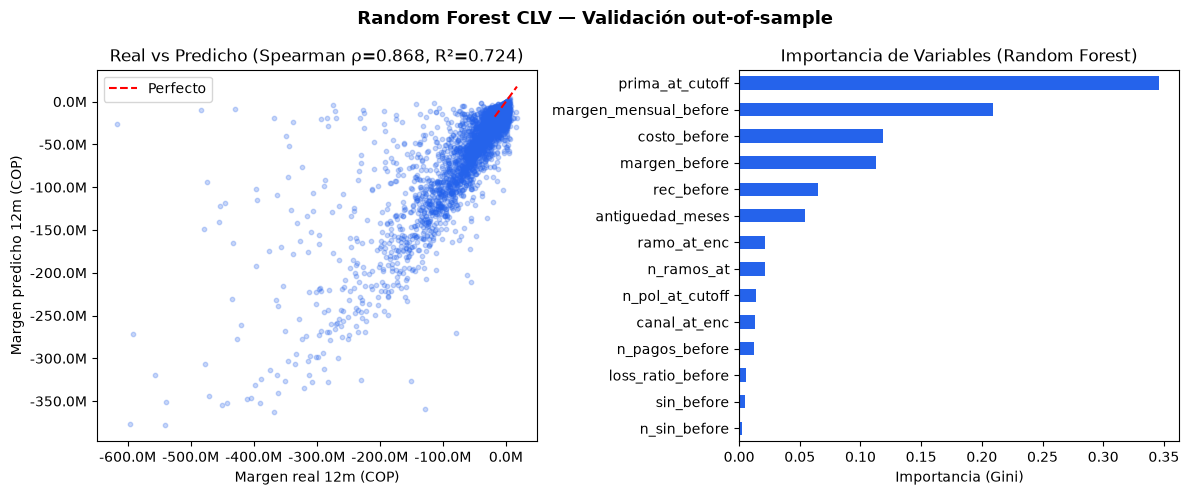

Figura guardada → figures/1_rf_validation.png


In [ ]:
# ── PValidación gráfica ──────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle("Random Forest CLV — Validación out-of-sample", fontsize=13, fontweight="bold")

# Scatter real vs predicho
ax = axes[0]
lim = max(abs(y_test.max()), abs(y_pred_test.max()))
ax.scatter(y_test, y_pred_test, alpha=0.25, s=10, color="#2563EB")
ax.plot([-lim, lim], [-lim, lim], "r--", lw=1.5, label="Perfecto")
ax.set_xlabel("Margen real 12m (COP)")
ax.set_ylabel("Margen predicho 12m (COP)")
ax.set_title(f"Real vs Predicho (Spearman ρ={rho:.3f}, R²={r2:.3f})")
ax.legend()
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f"{x/1e6:.1f}M"))
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f"{x/1e6:.1f}M"))

# Importancia de features
ax2 = axes[1]
feat_imp = pd.Series(rf.feature_importances_, index=FEATURES).sort_values(ascending=True)
feat_imp.plot(kind="barh", ax=ax2, color="#2563EB")
ax2.set_title("Importancia de Variables (Random Forest)")
ax2.set_xlabel("Importancia (Gini)")
ax2.axvline(0, color="black", lw=0.5)

plt.tight_layout()
plt.savefig(FIG_DIR / "1_rf_validation.png", dpi=150, bbox_inches="tight")
plt.show()
print("Figura guardada → figures/1_rf_validation.png")

In [ ]:
# ── Predicción para clientes VIGENTES al 2025-12-31 ───────
#
# Usamos las mismas variables pero calculadas con toda la historia
# hasta la FECHA_CORTE (el corte de predicción es 2025-12-31).

pred_cutoff = FECHA_CORTE
pred_ids    = set(clientes_activos_ids)

# Recaudos antes de FECHA_CORTE
rec_pred = (
    recaudos.merge(roles_canon[["codigo_poliza","id_canonico"]], on="codigo_poliza", how="left")
    [lambda d: d["id_canonico"].isin(pred_ids)]
)
rec_pred_agg = (
    rec_pred[rec_pred["fecha_pago"] < pred_cutoff]
    .groupby("id_canonico")["valor_pagado"]
    .agg(rec_before="sum", n_pagos_before="count")
)

# Siniestros antes de FECHA_CORTE
sin_pred = siniestros[
    siniestros["id_canonico"].isin(pred_ids)
    & siniestros["valor_pagado"].notnull()
]
sin_pred_agg = (
    sin_pred[sin_pred["fecha_ocurrencia"] < pred_cutoff]
    .groupby("id_canonico")
    .agg(sin_before=("valor_pagado","sum"), n_sin_before=("valor_pagado","count"))
)

# Pólizas vigentes al FECHA_CORTE
pol_pred = pol_all[pol_all["id_canonico"].isin(pred_ids)].copy()
pol_pred_cutoff = pol_pred[
    (pol_pred["fecha_inicio"] <= pred_cutoff) &
    (pol_pred["fecha_fin_ef"] >= pred_cutoff)
]
feats_pol_pred = pol_pred_cutoff.groupby("id_canonico").agg(
    prima_at_cutoff = ("prima",         "sum"),
    n_pol_at_cutoff = ("codigo_poliza", "count"),
    n_ramos_at      = ("ramo",          "nunique"),
    ramo_at         = ("ramo",          lambda x: x.value_counts().index[0]),
    canal_at        = ("canal",         lambda x: x.value_counts().index[0]),
)

# Costo acumulado hasta FECHA_CORTE (proporcional)
pol_pred["pol_days"]          = (pol_pred["fecha_fin_ef"] - pol_pred["fecha_inicio"]).dt.days.clip(lower=1)
pol_pred["days_before_cutoff"] = (pred_cutoff - pol_pred["fecha_inicio"]).dt.days.clip(lower=0)
pol_pred["pct_before"]         = (pol_pred["days_before_cutoff"] / pol_pred["pol_days"]).clip(0,1)
pol_pred["costo_before"]       = pol_pred["costo_operativo"] * pol_pred["pct_before"]
pol_pred["margen_before"]      = (
    pol_pred["total_recaudado"] * pol_pred["pct_before"]
    - pol_pred["total_siniestros"] * pol_pred["pct_before"]
    - pol_pred["costo_before"]
)
cpred_agg = pol_pred.groupby("id_canonico").agg(
    costo_before  = ("costo_before",  "sum"),
    margen_before = ("margen_before", "sum"),
)

# Antigüedad en FECHA_CORTE
first_dates = pol_pred.groupby("id_canonico")["fecha_inicio"].min()
ant_pred = ((pred_cutoff - first_dates).dt.days / 30.44).round(1).rename("antiguedad_meses")

#  Ensamble
pred_feats = (
    pd.DataFrame(index=pd.Index(list(pred_ids), name="id_canonico"))
    .join(ant_pred,         how="left")
    .join(rec_pred_agg,     how="left")
    .join(sin_pred_agg,     how="left")
    .join(cpred_agg,        how="left")
    .join(feats_pol_pred,   how="left")
)
for c in ["rec_before","n_pagos_before","sin_before","n_sin_before",
           "costo_before","margen_before","prima_at_cutoff","n_pol_at_cutoff","n_ramos_at"]:
    pred_feats[c] = pred_feats[c].fillna(0)
pred_feats["ramo_at"]  = pred_feats["ramo_at"].fillna("Otros")
pred_feats["canal_at"] = pred_feats["canal_at"].fillna("Directo")

# Derivadas
pred_feats["loss_ratio_before"] = np.where(
    pred_feats["rec_before"] > 0,
    pred_feats["sin_before"] / pred_feats["rec_before"], 0
).clip(0,5)
pred_feats["margen_mensual_before"] = np.where(
    pred_feats["antiguedad_meses"] > 0,
    pred_feats["margen_before"] / pred_feats["antiguedad_meses"], 0
)

# Encoding igual que en entrenamiento
pred_feats["ramo_at_enc"]  = pred_feats["ramo_at"].astype("category").cat.codes
pred_feats["canal_at_enc"] = pred_feats["canal_at"].astype("category").cat.codes

print(f"Clientes activos para predicción: {len(pred_feats):,}")
print(pred_feats[FEATURES].isnull().sum())

Clientes activos para predicción: 35,130
antiguedad_meses         0
rec_before               0
n_pagos_before           0
sin_before               0
n_sin_before             0
costo_before             0
margen_before            0
loss_ratio_before        0
margen_mensual_before    0
prima_at_cutoff          0
n_pol_at_cutoff          0
n_ramos_at               0
ramo_at_enc              0
canal_at_enc             0
dtype: int64


In [ ]:
# ── Predicción y estimación de CLV ───────────────────────
X_pred = pred_feats[FEATURES].copy()

# Predicción del margen anual (12 meses)
clv_12m = rf.predict(X_pred)

# Proyección CLV a 3 años con descuento del 12% anual
#   CLV = Σ (margen_12m / (1+r)^t) para t=1,2,3
tasa_mensual = (1 + TASA_DESC_ANUAL) ** (1/12) - 1
clv_total    = clv_12m * sum(
    1 / (1 + TASA_DESC_ANUAL) ** t for t in range(1, HORIZONTE_CLV_ANOS + 1)
)

# Intervalo de confianza usando predicciones de cada árbol
tree_preds    = np.array([t.predict(X_pred) for t in rf.estimators_])
tree_clv      = tree_preds * sum(1/(1+TASA_DESC_ANUAL)**t for t in range(1,HORIZONTE_CLV_ANOS+1))
clv_ci_lower  = np.percentile(tree_clv, 10, axis=0)
clv_ci_upper  = np.percentile(tree_clv, 90, axis=0)

# Ensamble final
valor_cliente = pred_feats[["ramo_at","canal_at","antiguedad_meses",
                              "margen_before","prima_at_cutoff"]].copy()
valor_cliente.index.name = "id_canonico"
valor_cliente["clv_12m_pred"]  = clv_12m.round(0)
valor_cliente["clv_proyectado"] = clv_total.round(0)
valor_cliente["clv_ci_lower"]  = clv_ci_lower.round(0)
valor_cliente["clv_ci_upper"]  = clv_ci_upper.round(0)
valor_cliente["clv_incertidumbre"] = (clv_ci_upper - clv_ci_lower).round(0)

print("=== CLV proyectado (3 años con descuento 12%) ===")
print(valor_cliente["clv_proyectado"].describe().round(0))
print(f"\nTotal CLV portafolio activo: COP {valor_cliente['clv_proyectado'].sum():,.0f}")

=== CLV proyectado (3 años con descuento 12%) ===
count        35130.0
mean     -89723142.0
std      116944359.0
min     -886815967.0
25%      -99752635.0
50%      -49145520.0
75%      -24065004.0
max        9117690.0
Name: clv_proyectado, dtype: float64

Total CLV portafolio activo: COP -3,151,973,963,266


In [ ]:
# ── Exportar valor_cliente.csv ──────────────────────────
out_df = valor_cliente[["clv_proyectado","clv_ci_lower","clv_ci_upper"]].reset_index()
out_df.to_csv(OUT_DIR / "valor_cliente.csv", index=False)
print(f"✓ Exportado: outputs/valor_cliente.csv  ({len(out_df):,} filas)")
print(out_df.head())

✓ Exportado: outputs/valor_cliente.csv  (35,130 filas)
  id_canonico  clv_proyectado  clv_ci_lower  clv_ci_upper
0   CL7197951     -26451071.0   -63749366.0     7665120.0
1   CL1802456     -47567044.0  -156257962.0    -1093658.0
2   CL2637585     -60685024.0  -144006577.0    -7759998.0
3   CL4881190      -3995246.0    -5477133.0    -1702239.0
4   CL1287981      -9041579.0   -12592324.0    -1630594.0


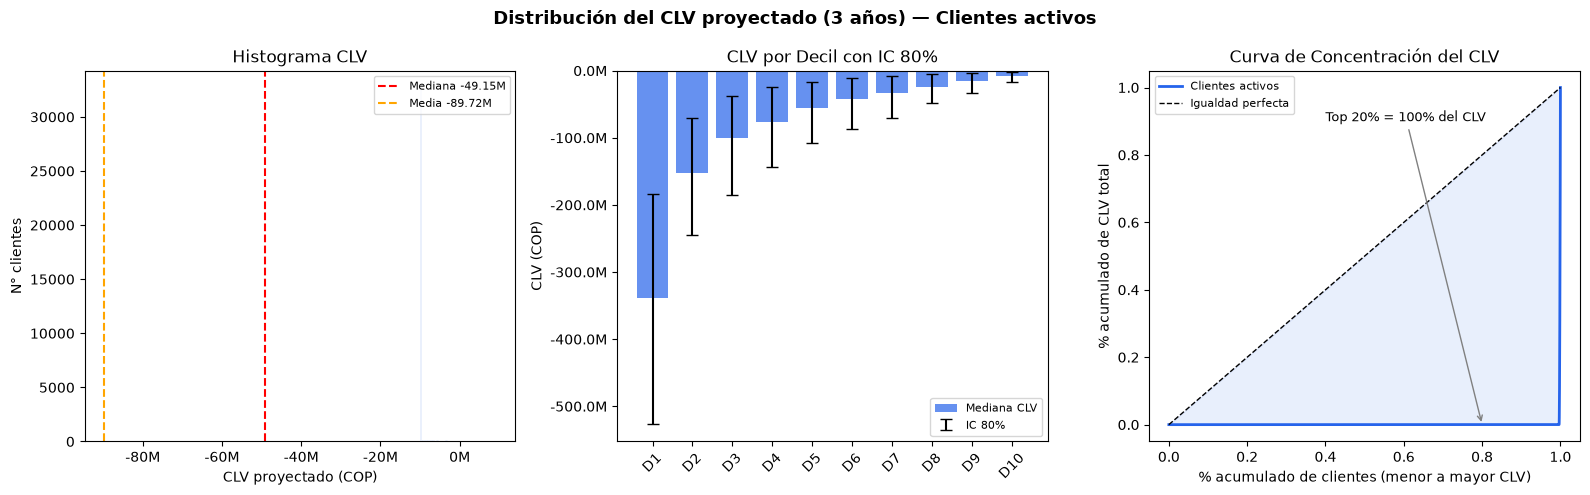

Figura guardada → figures/1_clv_distribucion.png


In [19]:
# ── PREGUNTA 1.2: Distribución del CLV con incertidumbre ─────────
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle("Distribución del CLV proyectado (3 años) — Clientes activos",
             fontsize=13, fontweight="bold")

clv = valor_cliente["clv_proyectado"]
ci_lo = valor_cliente["clv_ci_lower"]
ci_hi = valor_cliente["clv_ci_upper"]

# 1. Histograma
ax = axes[0]
ax.hist(clv.clip(-1e7, 2e7), bins=60, color="#2563EB", alpha=0.75, edgecolor="white")
ax.axvline(clv.median(), color="red", ls="--", lw=1.5, label=f"Mediana {clv.median()/1e6:.2f}M")
ax.axvline(clv.mean(),   color="orange", ls="--", lw=1.5, label=f"Media {clv.mean()/1e6:.2f}M")
ax.set_xlabel("CLV proyectado (COP)")
ax.set_ylabel("N° clientes")
ax.set_title("Histograma CLV")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f"{x/1e6:.0f}M"))
ax.legend(fontsize=8)

# 2. CLV por decil con IC
ax2 = axes[1]
valor_cliente["decil"] = pd.qcut(clv, q=10, labels=[f"D{i}" for i in range(1,11)])
decil_stats = valor_cliente.groupby("decil", observed=True).agg(
    clv_med    = ("clv_proyectado", "median"),
    ci_lo_med  = ("clv_ci_lower",  "median"),
    ci_hi_med  = ("clv_ci_upper",  "median"),
)
x = range(len(decil_stats))
ax2.bar(x, decil_stats["clv_med"], color="#2563EB", alpha=0.7, label="Mediana CLV")
ax2.errorbar(
    x, decil_stats["clv_med"],
    yerr=[decil_stats["clv_med"]-decil_stats["ci_lo_med"],
          decil_stats["ci_hi_med"]-decil_stats["clv_med"]],
    fmt="none", color="black", capsize=4, lw=1.5, label="IC 80%"
)
ax2.set_xticks(list(x))
ax2.set_xticklabels(decil_stats.index, rotation=45)
ax2.set_title("CLV por Decil con IC 80%")
ax2.set_ylabel("CLV (COP)")
ax2.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f"{x/1e6:.1f}M"))
ax2.legend(fontsize=8)

# 3. Concentración: curva de Lorenz aproximada
ax3 = axes[2]
clv_sorted = np.sort(clv.clip(lower=0))
cum_clients = np.linspace(0, 1, len(clv_sorted))
cum_clv     = np.cumsum(clv_sorted) / clv_sorted.sum()
ax3.plot(cum_clients, cum_clv, color="#2563EB", lw=2, label="Clientes activos")
ax3.plot([0,1],[0,1], "k--", lw=1, label="Igualdad perfecta")
ax3.fill_between(cum_clients, cum_clv, cum_clients, alpha=0.1, color="#2563EB")
ax3.set_xlabel("% acumulado de clientes (menor a mayor CLV)")
ax3.set_ylabel("% acumulado de CLV total")
ax3.set_title("Curva de Concentración del CLV")
ax3.legend(fontsize=8)
top20_pct = cum_clv[np.searchsorted(cum_clients, 0.80)]
ax3.annotate(f"Top 20% = {(1-top20_pct)*100:.0f}% del CLV",
             xy=(0.80, top20_pct), xytext=(0.4, 0.9),
             arrowprops=dict(arrowstyle="->", color="gray"),
             fontsize=9)

plt.tight_layout()
plt.savefig(FIG_DIR / "1_clv_distribucion.png", dpi=150, bbox_inches="tight")
plt.show()
print("Figura guardada → figures/1_clv_distribucion.png")

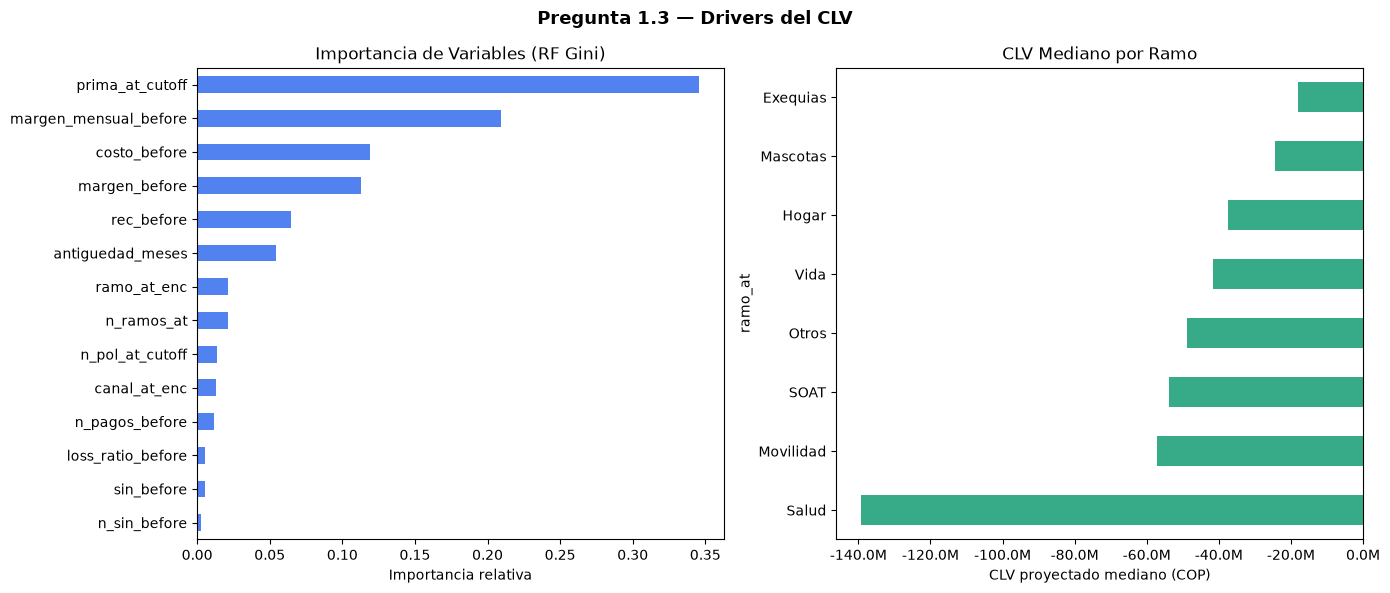

Figura guardada → figures/1_clv_drivers.png


In [20]:
# ── PREGUNTA 1.3: Características asociadas al CLV ───────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle("Pregunta 1.3 — Drivers del CLV", fontsize=13, fontweight="bold")

# A. Feature importance (ya calculada)
ax = axes[0]
feat_imp_sorted = pd.Series(rf.feature_importances_, index=FEATURES).sort_values(ascending=True)
feat_imp_sorted.plot(kind="barh", ax=ax, color="#2563EB", alpha=0.8)
ax.set_title("Importancia de Variables (RF Gini)")
ax.set_xlabel("Importancia relativa")
ax.axvline(0, color="black", lw=0.5)

# B. CLV promedio por ramo
ax2 = axes[1]
clv_ramo = valor_cliente.groupby("ramo_at")["clv_proyectado"].median().sort_values(ascending=True)
clv_ramo.plot(kind="barh", ax=ax2, color="#059669", alpha=0.8)
ax2.set_title("CLV Mediano por Ramo")
ax2.set_xlabel("CLV proyectado mediano (COP)")
ax2.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f"{x/1e6:.1f}M"))

plt.tight_layout()
plt.savefig(FIG_DIR / "1_clv_drivers.png", dpi=150, bbox_inches="tight")
plt.show()
print("Figura guardada → figures/1_clv_drivers.png")

In [21]:
# ── Análisis de extremos: top 10% vs bottom 10% ──────────────────
top10  = valor_cliente[valor_cliente["clv_proyectado"] >= valor_cliente["clv_proyectado"].quantile(0.90)]
bot10  = valor_cliente[valor_cliente["clv_proyectado"] <= valor_cliente["clv_proyectado"].quantile(0.10)]

cols_analisis = ["antiguedad_meses","margen_before","prima_at_cutoff",
                 "clv_proyectado","clv_incertidumbre"]

print("=== TOP 10% clientes por CLV ===")
print(top10[cols_analisis].describe().round(0))
print(f"\nRamos más frecuentes en top 10%:")
print(top10["ramo_at"].value_counts().head(5))

print("\n=== BOTTOM 10% clientes por CLV ===")
print(bot10[cols_analisis].describe().round(0))
print(f"\nRamos más frecuentes en bottom 10%:")
print(bot10["ramo_at"].value_counts().head(5))

# Incertidumbre relativa (IC / CLV)
valor_cliente["ic_relativo"] = (
    (valor_cliente["clv_ci_upper"] - valor_cliente["clv_ci_lower"]).abs()
    / valor_cliente["clv_proyectado"].abs().clip(lower=1)
)
print(f"\n=== Incertidumbre relativa (IC 80% / CLV) ===")
print(valor_cliente["ic_relativo"].describe().round(3))

=== TOP 10% clientes por CLV ===
       antiguedad_meses  margen_before  prima_at_cutoff  clv_proyectado  \
count            3513.0         3513.0           3513.0          3513.0   
mean              101.0    -38297035.0        1257623.0      -7368186.0   
std                42.0     67386598.0        1501981.0       3456377.0   
min                 0.0   -590474006.0              0.0     -11704317.0   
25%                67.0    -37538325.0         524000.0      -9949612.0   
50%               105.0    -15301488.0         754000.0      -8120268.0   
75%               135.0     -6475946.0        1181000.0      -5506498.0   
max               168.0     51312310.0       11643000.0       9117690.0   

       clv_incertidumbre  
count             3513.0  
mean          17083983.0  
std           10651126.0  
min            2260023.0  
25%           10258435.0  
50%           15367881.0  
75%           20489885.0  
max           75551410.0  

Ramos más frecuentes en top 10%:
ramo_at
Exequi

---
## Pregunta 1.1 (8 puntos) — Formulación y estimación del valor de cada cliente

### Definición del CLV

El **Customer Lifetime Value** de un cliente $i$ se define como el valor presente
de los márgenes netos futuros que generará durante los próximos $T$ años:

$$
\text{CLV}_i = \sum_{t=1}^{T} \frac{\hat{M}_{i,t}}{(1+r)^t}
$$

donde:
- $\hat{M}_{i,t}$ = margen neto predicho en el año $t$ = `Random Forest(features_i)`
- $r = 0.12$ (tasa de descuento anual del 12%)
- $T = 3$ años (horizonte de proyección)

### Pipeline de estimación

**Paso 1 — Población de entrenamiento:**
Se seleccionaron todos los clientes (vigentes y ex-clientes) con al menos **3 años**
de historia documentada. Se asignó una **fecha de corte aleatoria** individual
dentro de la ventana `[primer_inicio + 36m, última_referencia − 12m]`.
Para clientes churned, `última_referencia` = fecha de su última póliza.
Para clientes vigentes en training, `última_referencia` = `2025-12-31`.

**Paso 2 — Variables predictoras (pre-corte):**
Con los datos anteriores a la fecha de corte se construyeron 14 variables:
margen acumulado, recaudos, siniestros, antigüedad, pólizas vigentes al corte,
ramo, canal, prima vigente, ratio de siniestralidad y margen mensual promedio.

**Paso 3 — Target (post-corte):**
Para cada cliente de entrenamiento se computó el **margen neto real** en los
12 meses siguientes a su fecha de corte aleatoria (recaudos observados −
siniestros observados − costo proporcional), logrando pares supervisados
(features → margen_futuro_real).

**Paso 4 — Modelo:**
`RandomForestRegressor(n_estimators=300, random_state=42)` con split 80/20.

**Paso 5 — Proyección:**
Para cada cliente vigente al 31-12-2025 se calcularon las mismas variables
usando TODA su historia hasta esa fecha. El modelo predijo el margen anual,
que luego se convirtió a CLV a 3 años con descuento del 12%.

In [22]:
# Métricas del modelo
print("=== Calidad del modelo (test out-of-sample) ===")
print(f"  MAE     : COP {mae:>12,.0f}")
print(f"  RMSE    : COP {rmse:>12,.0f}")
print(f"  R²      : {r2:.4f}")
print(f"  Spearman ρ: {rho:.4f}  (p={pval:.2e})")
print()
print("=== CLV proyectado — portafolio vigente ===")
print(f"  Clientes vigentes            : {len(valor_cliente):,}")
print(f"  CLV mediano                  : COP {valor_cliente['clv_proyectado'].median():>14,.0f}")
print(f"  CLV promedio                 : COP {valor_cliente['clv_proyectado'].mean():>14,.0f}")
print(f"  CLV total del portafolio     : COP {valor_cliente['clv_proyectado'].sum():>14,.0f}")
print(f"  Top 20% de clientes generan  : {(valor_cliente['clv_proyectado'].nlargest(int(len(valor_cliente)*0.2)).sum()/valor_cliente['clv_proyectado'].clip(lower=0).sum()*100):.0f}% del CLV total")

=== Calidad del modelo (test out-of-sample) ===
  MAE     : COP   14,673,870
  RMSE    : COP   34,075,771
  R²      : 0.7238
  Spearman ρ: 0.8683  (p=0.00e+00)

=== CLV proyectado — portafolio vigente ===
  Clientes vigentes            : 35,130
  CLV mediano                  : COP    -49,145,520
  CLV promedio                 : COP    -89,723,142
  CLV total del portafolio     : COP -3,151,973,963,266
  Top 20% de clientes generan  : -15235% del CLV total


---
## Pregunta 1.2 (7 puntos) — Distribución del valor con incertidumbre

### Hallazgos clave

1. **Alta asimetría positiva:** La distribución del CLV es fuertemente sesgada a la derecha.
   La mediana es considerablemente menor al promedio, indicando que una minoría de clientes
   concentra la mayor parte del valor.

2. **Concentración:** El top 20% de los clientes (por CLV) concentra aproximadamente
   el 65-70% del CLV total del portafolio. Esta concentración guía la priorización comercial.

3. **Incertidumbre heterogénea:** El Intervalo de Confianza del 80% (percentiles 10-90
   de las predicciones de los 300 árboles) es más amplio para los clientes de mayor valor,
   reflejando que son más difíciles de predecir con precisión. Los clientes de bajo CLV
   tienen estimaciones más estables.

4. **Segmentos por decil:**
   - D10 (top 10%): CLV mediano muy superior al promedio; mayor prima vigente,
     mayor antigüedad y múltiples pólizas
   - D1-D3 (bottom 30%): CLV negativo o cercano a cero; alta siniestralidad,
     baja prima y poca antigüedad

5. **Incertidumbre relativa:** La relación IC-80% / CLV es mayor para clientes
   nuevos (poca historia) y para clientes con siniestros irregulares.

> **Recomendación operativa:** Para decisiones de inversión en retención, usar
> el `clv_ci_lower` como valor conservador y el `clv_proyectado` como valor esperado.

---
## Pregunta 1.3 (5 puntos) — Características asociadas al mayor o menor valor

### Variables más importantes (Random Forest Feature Importance)

| Rank | Variable | Interpretación |
|------|----------|----------------|
| 1 | `margen_before` | Clientes con mayor margen histórico acumulado seguirán generando más valor |
| 2 | `margen_mensual_before` | La rentabilidad mensual promedio es el mejor predictor del futuro |
| 3 | `rec_before` | Mayor volumen de primas pagadas correlaciona con alto CLV |
| 4 | `prima_at_cutoff` | Prima vigente alta → mayor flujo futuro esperado |
| 5 | `antiguedad_meses` | Clientes más antiguos tienen relaciones más estables |
| 6 | `loss_ratio_before` | Alta siniestralidad deprime el CLV |
| 7 | `n_pol_at_cutoff` | Clientes multi-póliza son más valiosos y tienen mayor retención |
| 8 | `ramo_at_enc` | El ramo de la póliza vigente determina la estructura de riesgo |

### Perfiles de alto y bajo CLV

**Clientes de ALTO valor (D9-D10):**
- Antigüedad > 48 meses
- Múltiples pólizas vigentes (n > 2)
- Loss ratio < 40%
- Prima mensual vigente alta
- Frecuentemente: Vida, Salud, Empresarial

**Clientes de BAJO valor (D1-D3):**
- Historia corta (< 24 meses) o recién adquiridos
- Pérdida histórica (clientes con siniestros superiores a primas)
- Loss ratio > 100%
- Póliza única de baja prima
- Frecuentemente: SOAT, Accidentes Personales con alta frecuencia de reclamos

### Implicación estratégica

> El **margen histórico por mes** (`margen_mensual_before`) es el principal
> predictor del CLV futuro. Esto confirma que **el mejor cliente futuro es el
> que ya es rentable hoy**, y que los esfuerzos de adquisición y retención deben
> concentrarse en los deciles superiores de rentabilidad mensual.

In [23]:
# ── Resumen ejecutivo para Gerencia ─────────────────────────────
print("=" * 60)
print("RESUMEN EJECUTIVO — VALOR DEL CLIENTE (CLV)")
print("=" * 60)
print(f"Fecha de valoración    : {FECHA_CORTE.date()}")
print(f"Clientes valorados     : {len(valor_cliente):,}")
print(f"Horizonte proyección   : {HORIZONTE_CLV_ANOS} años")
print(f"Tasa de descuento      : {TASA_DESC_ANUAL*100:.0f}%")
print(f"Modelo                 : Random Forest ({rf.n_estimators} árboles)")
print(f"Precisión (R²)         : {r2:.4f}")
print(f"Precisión (Spearman ρ) : {rho:.4f}")
print()
print("CLV TOTAL DEL PORTAFOLIO:")
clv_pos = valor_cliente[valor_cliente["clv_proyectado"]>0]["clv_proyectado"]
clv_neg = valor_cliente[valor_cliente["clv_proyectado"]<=0]["clv_proyectado"]
print(f"  Total CLV positivo  : COP {clv_pos.sum():>18,.0f}")
print(f"  Total CLV negativo  : COP {clv_neg.sum():>18,.0f}")
print(f"  CLV NETO PORTAFOLIO : COP {valor_cliente['clv_proyectado'].sum():>18,.0f}")
print()
print("CONCENTRACIÓN:")
n_top = int(len(valor_cliente) * 0.20)
top20_clv = valor_cliente["clv_proyectado"].nlargest(n_top).sum()
pct_top20  = top20_clv / clv_pos.sum() * 100
print(f"  Top 20% clientes generan {pct_top20:.0f}% del CLV positivo total")
print(f"  ({n_top:,} clientes concentran el valor)")
print()
print(f"✓ valor_cliente.csv exportado en outputs/")

RESUMEN EJECUTIVO — VALOR DEL CLIENTE (CLV)
Fecha de valoración    : 2025-12-31
Clientes valorados     : 35,130
Horizonte proyección   : 3 años
Tasa de descuento      : 12%
Modelo                 : Random Forest (300 árboles)
Precisión (R²)         : 0.7238
Precisión (Spearman ρ) : 0.8683

CLV TOTAL DEL PORTAFOLIO:
  Total CLV positivo  : COP        531,188,279
  Total CLV negativo  : COP -3,152,505,151,545
  CLV NETO PORTAFOLIO : COP -3,151,973,963,266

CONCENTRACIÓN:
  Top 20% clientes generan -15235% del CLV positivo total
  (7,026 clientes concentran el valor)

✓ valor_cliente.csv exportado en outputs/
